# Poisson vs. Negative Binomial for RNA-seq Read Counts

**Question.** Why do RNA-seq pipelines (DESeq2, edgeR) model counts with a Negative Binomial (NB) instead of a Poisson?

**Short answer (what this note shows).** Biological replicates are *overdispersed* (variance > mean). A Poisson model ignores this, fits the tails badly, and, in a simple null experiment, produces far more false positives than its nominal 5% level. An NB model with a dispersion parameter fixes this.

**Scope.** This is a deliberately simplified, single-gene simulation. Real experiments have few replicates (typically 3-6) and thousands of genes with different means; dispersion is then estimated per gene with information sharing across genes (empirical Bayes shrinkage). Section 5 shows the consequence of overdispersion with small replicate numbers; the limitations are listed at the end.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
from scipy.optimize import minimize
import seaborn as sns
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# Figures are saved to <repo>/assets so the README can embed them.
ASSETS = (Path.cwd().parent if Path.cwd().name == "notes" else Path.cwd()) / "assets"
ASSETS.mkdir(exist_ok=True)

## 1. Synthetic data from a known ground truth

For technical replicates (same library split and sequenced repeatedly), counts are close to Poisson: $\sigma^2 = \mu$. Biological replicates add extra variability (transcriptional bursting, environment, ...), so that

$$\sigma^2 = \mu + \alpha\mu^2, \qquad \alpha > 0 \text{ is the dispersion.}$$

This is a Gamma-Poisson mixture, i.e. a Negative Binomial. We draw $N = 1000$ counts from an NB with $\mu_{\text{true}} = 50$ and $\alpha_{\text{true}} = 0.25$, so $\sigma^2_{\text{true}} = 50 + 0.25 \cdot 50^2 = 675$.

> **Interpretation.** These 1000 values are best read as 1000 independent replicate measurements of *one* gene (or of 1000 genes that all happen to share the same mean and dispersion). Real data never look like this; see the limitations section.

SciPy's `nbinom(n, p)` uses a different parametrization, so we convert: $n = 1/\alpha$, $p = 1/(1 + \alpha\mu)$.

In [2]:
def alpha_mu_to_scipy_nb(alpha: float, mu: float) -> tuple[float, float]:
    """Convert (mu, alpha) with Var = mu + alpha * mu^2 to scipy's nbinom (n, p)."""
    if alpha <= 0 or mu <= 0:
        raise ValueError(f"alpha ({alpha}) and mu ({mu}) must be positive.")
    return 1.0 / alpha, 1.0 / (1.0 + alpha * mu)


MU_TRUE, ALPHA_TRUE, N_OBS = 50.0, 0.25, 1000
VAR_TRUE = MU_TRUE + ALPHA_TRUE * MU_TRUE**2          # 675.0

n_scipy, p_scipy = alpha_mu_to_scipy_nb(ALPHA_TRUE, MU_TRUE)
counts = stats.nbinom.rvs(n=n_scipy, p=p_scipy, size=N_OBS, random_state=rng)

print(f"SciPy parameters   -> n: {n_scipy:.4f}, p: {p_scipy:.4f}")
print(f"Sample mean        (true {MU_TRUE:.0f}):  {counts.mean():.2f}")
print(f"Sample variance    (true {VAR_TRUE:.0f}): {counts.var(ddof=1):.2f}")

SciPy parameters   -> n: 4.0000, p: 0.0741
Sample mean        (true 50):  50.35
Sample variance    (true 675): 650.46


## 2. Fitting both models by the method of moments

Treat `counts` as observed data with unknown parameters.

* **Poisson:** one parameter, $\hat\mu = \bar x$; the variance is forced to equal the mean.
* **Negative Binomial (method of moments):** match the sample mean $\bar x$ and unbiased sample variance $s^2$ (`ddof=1`):
  $\hat n = \dfrac{\bar x^2}{s^2 - \bar x}$, $\hat p = \dfrac{\bar x}{s^2}$, and $\hat\alpha = 1/\hat n$.

The method of moments is quick and transparent. Section 4 compares it with maximum likelihood.

In [3]:
def fit_nb_moments(mean: float, variance: float) -> tuple[float, float]:
    """Method-of-moments NB fit; returns scipy's (n, p). Requires overdispersion."""
    if variance <= mean:
        raise ValueError("Variance must exceed the mean (no overdispersion detected).")
    return mean**2 / (variance - mean), mean / variance


sample_mean = float(counts.mean())
sample_var = float(counts.var(ddof=1))

n_hat, p_hat = fit_nb_moments(sample_mean, sample_var)
alpha_hat = 1.0 / n_hat

k_grid = np.arange(0, counts.max() + 1)
poisson_pmf = stats.poisson.pmf(k_grid, mu=sample_mean)
nb_pmf = stats.nbinom.pmf(k_grid, n=n_hat, p=p_hat)

print(f"Poisson: mu = {sample_mean:.2f}")
print(f"NB (MoM): mu = {sample_mean:.2f}, alpha_hat = {alpha_hat:.3f} (true {ALPHA_TRUE})")

Poisson: mu = 50.35
NB (MoM): mu = 50.35, alpha_hat = 0.237 (true 0.25)


## 3. Visual check: histogram vs. fitted PMFs

The histogram uses integer-aligned bins of width 5 (`stat="density"`), so its heights are directly comparable to the PMFs (probability per unit count).

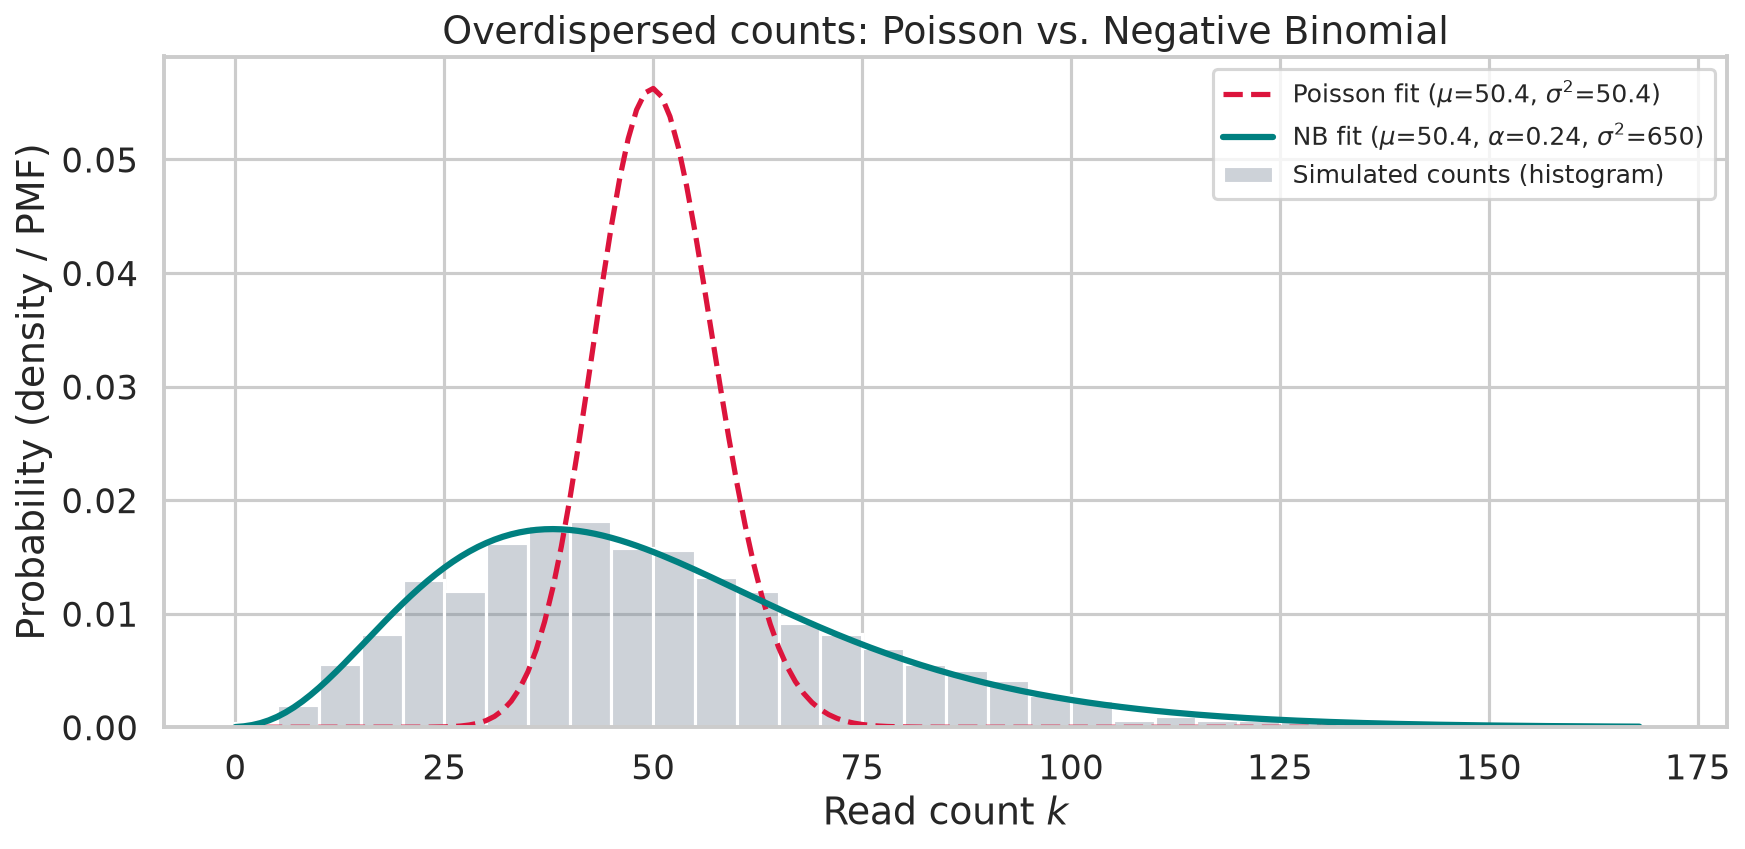

In [4]:
sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(12, 6), dpi=150)

bin_width = 5
bins = np.arange(0, counts.max() + bin_width + 1, bin_width)
sns.histplot(counts, bins=bins, stat="density", color="slategray", alpha=0.35,
             label="Simulated counts (histogram)", ax=ax)
ax.plot(k_grid, poisson_pmf, color="crimson", ls="--", lw=2.5,
        label=f"Poisson fit ($\\mu$={sample_mean:.1f}, $\\sigma^2$={sample_mean:.1f})")
ax.plot(k_grid, nb_pmf, color="teal", lw=3,
        label=f"NB fit ($\\mu$={sample_mean:.1f}, $\\alpha$={alpha_hat:.2f}, $\\sigma^2$={sample_var:.0f})")

ax.set_title("Overdispersed counts: Poisson vs. Negative Binomial")
ax.set_xlabel("Read count $k$")
ax.set_ylabel("Probability (density / PMF)")
ax.legend(frameon=True, fontsize=12)
fig.tight_layout()
fig.savefig(ASSETS / "01_poisson_vs_nb.png", bbox_inches="tight")
plt.show()

### Tail probabilities

The Poisson fit has standard deviation $\sqrt{50} \approx 7$, so it treats counts above 80 (about 4 SDs out) as almost impossible. Under the data-generating NB, such counts are routine. We quantify this with $P(K > 80)$:

In [5]:
THRESH = 80
tail_table = pd.DataFrame({
    "Source": ["Empirical (simulated data)", "Poisson fit", "NB fit (MoM)", "Ground truth (NB)"],
    f"P(K > {THRESH})": [
        np.mean(counts > THRESH),
        stats.poisson.sf(THRESH, sample_mean),
        stats.nbinom.sf(THRESH, n_hat, p_hat),
        stats.nbinom.sf(THRESH, n_scipy, p_scipy),
    ],
})
print(tail_table.to_string(index=False, float_format=lambda x: f"{x:.5f}"))

                    Source  P(K > 80)
Empirical (simulated data)    0.11800
               Poisson fit    0.00004
              NB fit (MoM)    0.12165
         Ground truth (NB)    0.12275


## 4. Goodness of fit: log-likelihood and AIC

$\text{AIC} = 2k - 2\ell$ with $k$ free parameters (Poisson: 1, NB: 2); lower is better. AIC formally assumes maximum-likelihood estimates, so besides the method-of-moments NB we also compute the **maximum-likelihood** NB fit (numerical optimization over $\log\mu$ and $\log\alpha$, started at the moment estimates).

In [6]:
def nb_negloglik(params, x):
    mu, alpha = np.exp(params)                      # optimize on log scale -> positivity
    n, p = alpha_mu_to_scipy_nb(alpha, mu)
    return -stats.nbinom.logpmf(x, n, p).sum()


res = minimize(nb_negloglik, x0=np.log([sample_mean, alpha_hat]), args=(counts,),
               method="Nelder-Mead")
mu_mle, alpha_mle = np.exp(res.x)
n_mle, p_mle = alpha_mu_to_scipy_nb(alpha_mle, mu_mle)

ll_pois = stats.poisson.logpmf(counts, sample_mean).sum()
ll_nb_mom = stats.nbinom.logpmf(counts, n_hat, p_hat).sum()
ll_nb_mle = stats.nbinom.logpmf(counts, n_mle, p_mle).sum()

summary = pd.DataFrame({
    "Model": ["Ground truth", "Poisson (MLE)", "NB (method of moments)", "NB (MLE)"],
    "mu": [MU_TRUE, sample_mean, sample_mean, mu_mle],
    "alpha": [ALPHA_TRUE, 0.0, alpha_hat, alpha_mle],
    "Variance": [VAR_TRUE, sample_mean, sample_var, mu_mle + alpha_mle * mu_mle**2],
    "Log-lik": [np.nan, ll_pois, ll_nb_mom, ll_nb_mle],
    "AIC": [np.nan, 2 * 1 - 2 * ll_pois, 2 * 2 - 2 * ll_nb_mom, 2 * 2 - 2 * ll_nb_mle],
})
print(summary.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(f"\nDelta AIC (Poisson - NB MLE): {summary.AIC[1] - summary.AIC[3]:.1f}")

                 Model     mu  alpha  Variance   Log-lik       AIC
          Ground truth 50.000  0.250   675.000       NaN       NaN
         Poisson (MLE) 50.351  0.000    50.351 -9078.802 18159.604
NB (method of moments) 50.351  0.237   650.460 -4581.762  9167.524
              NB (MLE) 50.351  0.241   662.217 -4581.678  9167.357

Delta AIC (Poisson - NB MLE): 8992.2


MoM and MLE give nearly the same NB fit here, which is expected with $N = 1000$. The AIC gap against Poisson is enormous, so the data strongly reject equidispersion.

## 5. Consequence: false positives in a null experiment

Overdispersion matters in practice because it breaks the **calibration** of tests. Setup:

* Two conditions with $r$ replicates each, **both drawn from the same NB** ($\mu = 50$, $\alpha = 0.25$). By construction there is *no* true difference, so a well-calibrated test at level 0.05 should reject in about 5% of experiments.
* Test the difference between conditions with a **likelihood-ratio test** (1 degree of freedom) under (a) a Poisson model and (b) an NB model with the dispersion fixed at its true value.
* Repeat for 10,000 simulated experiments per setting.

Fixing $\alpha$ at the truth is a best case for the NB; real tools must estimate $\alpha$ from few replicates, which is why they borrow strength across genes.

In [7]:
def lrt_two_group(g1, g2, family, alpha=None):
    """LRT for equal means across two groups. g1, g2: arrays (n_experiments, r)."""
    eps = 1e-10

    def loglik(x, mu):
        mu = np.maximum(mu, eps)
        if family == "poisson":
            return stats.poisson.logpmf(x, mu).sum(axis=1)
        n, p = 1.0 / alpha, 1.0 / (1.0 + alpha * mu)
        return stats.nbinom.logpmf(x, n, p).sum(axis=1)

    m1, m2 = g1.mean(axis=1, keepdims=True), g2.mean(axis=1, keepdims=True)
    pooled = np.concatenate([g1, g2], axis=1)
    m0 = pooled.mean(axis=1, keepdims=True)
    stat = 2 * (loglik(g1, m1) + loglik(g2, m2) - loglik(g1, m0) - loglik(g2, m0))
    return stats.chi2.sf(np.maximum(stat, 0), df=1)


N_EXPERIMENTS, LEVEL = 10_000, 0.05
n_s, p_s = alpha_mu_to_scipy_nb(ALPHA_TRUE, MU_TRUE)
rows = []
for r in (3, 6):
    g1 = stats.nbinom.rvs(n_s, p_s, size=(N_EXPERIMENTS, r), random_state=rng)
    g2 = stats.nbinom.rvs(n_s, p_s, size=(N_EXPERIMENTS, r), random_state=rng)
    for name, fam, a in (("Poisson LRT", "poisson", None),
                         ("NB LRT (true alpha)", "nb", ALPHA_TRUE)):
        fpr = np.mean(lrt_two_group(g1, g2, fam, a) < LEVEL)
        se = np.sqrt(fpr * (1 - fpr) / N_EXPERIMENTS)
        rows.append({"Replicates / group": r, "Test": name,
                     "False-positive rate": fpr, "95% CI +/-": 1.96 * se})

fpr_table = pd.DataFrame(rows)
print(f"Nominal level: {LEVEL:.2f}\n")
print(fpr_table.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

Nominal level: 0.05

 Replicates / group                Test  False-positive rate  95% CI +/-
                  3         Poisson LRT                0.595       0.010
                  3 NB LRT (true alpha)                0.055       0.004
                  6         Poisson LRT                0.589       0.010
                  6 NB LRT (true alpha)                0.048       0.004


## Takeaways and limitations

**Takeaways**

1. With $\alpha = 0.25$ the variance is 13x the mean; Poisson cannot represent this and badly underestimates tail probabilities.
2. Likelihood and AIC overwhelmingly favour the NB, and MoM and MLE agree closely at $N = 1000$.
3. In a null experiment, the Poisson test rejects far more often than the nominal 5%, whereas the NB test stays close to it.

**Limitations (not covered here)**

* One gene / one shared mean; real data have thousands of genes with widely varying means, and dispersion often depends on the mean.
* The NB test uses the *true* $\alpha$. With 3-6 replicates, estimating $\alpha$ per gene is noisy, which is why DESeq2/edgeR shrink dispersion estimates toward a fitted trend.
* No library-size normalization, zero inflation (relevant for single-cell data), batch effects or multiple-testing correction.
* The LRT's $\chi^2$ reference is asymptotic; for very small $r$ it is only approximate (visible in the NB row).

**References**

* Anders & Huber (2010), *Differential expression analysis for sequence count data*, Genome Biology.
* Love, Huber & Anders (2014), *Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2*, Genome Biology.
* Marioni et al. (2008), *RNA-seq: an assessment of technical reproducibility*, Genome Research.